In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

plt.rcParams['figure.dpi'] = 120

In [2]:
df_insurance = pd.read_csv("medical-charges.csv")

print("===== Insurance Dataset Preview =====")
print(df_insurance.head())
print("\n===== Insurance Dataset Info =====")
print(df_insurance.info())

===== Insurance Dataset Preview =====
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

===== Insurance Dataset Info =====
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None


In [3]:
df_heart = pd.read_csv("heart.csv")

print("===== Heart Disease Dataset Preview =====")
print(df_heart.head())
print("\n===== Heart Disease Dataset Info =====")
print(df_heart.info())

# Convert label to numeric: Present=1, Absent=0
df_heart["Heart_Disease_Binary"] = df_heart["Heart Disease"].map({"Present":1, "Absent":0})

===== Heart Disease Dataset Preview =====
   Age  Sex  Chest pain type   BP  Cholesterol  FBS over 120  EKG results  \
0   70    1                4  130          322             0            2   
1   67    0                3  115          564             0            2   
2   57    1                2  124          261             0            0   
3   64    1                4  128          263             0            0   
4   74    0                2  120          269             0            2   

   Max HR  Exercise angina  ST depression  Slope of ST  \
0     109                0            2.4            2   
1     160                0            1.6            2   
2     141                0            0.3            1   
3     105                1            0.2            2   
4     121                1            0.2            1   

   Number of vessels fluro  Thallium Heart Disease  
0                        3         3      Presence  
1                        0         7    

In [5]:
print("===== Insurance Summary Stats =====")
print(df_insurance[["bmi", "charges"]].describe())

print("\n===== Heart Disease Summary Stats =====")
print(df_heart[["Age", "Heart_Disease_Binary"]].describe())

===== Insurance Summary Stats =====
               bmi       charges
count  1338.000000   1338.000000
mean     30.663397  13270.422265
std       6.098187  12110.011237
min      15.960000   1121.873900
25%      26.296250   4740.287150
50%      30.400000   9382.033000
75%      34.693750  16639.912515
max      53.130000  63770.428010

===== Heart Disease Summary Stats =====
              Age  Heart_Disease_Binary
count  270.000000                   0.0
mean    54.433333                   NaN
std      9.109067                   NaN
min     29.000000                   NaN
25%     48.000000                   NaN
50%     55.000000                   NaN
75%     61.000000                   NaN
max     77.000000                   NaN


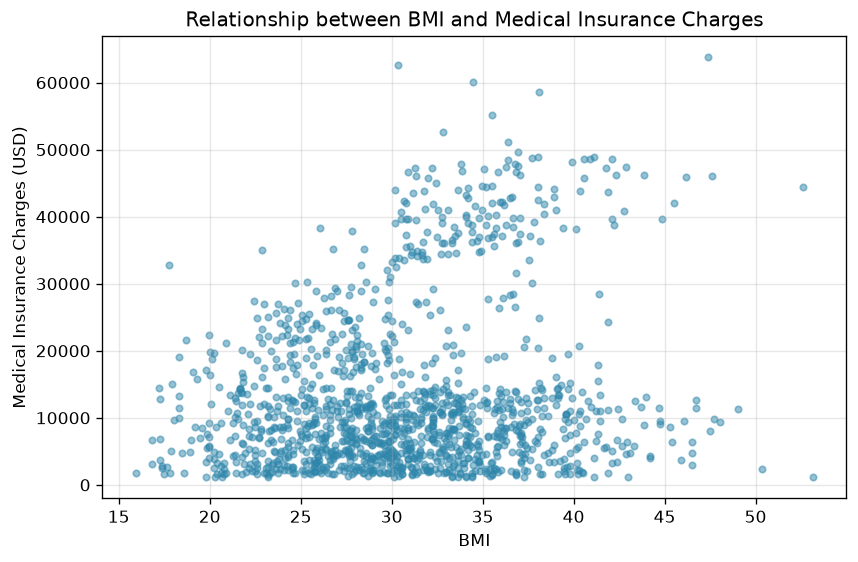

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df_insurance["bmi"], df_insurance["charges"], alpha=0.5, s=15, color="#2E86AB")

plt.xlabel("BMI")
plt.ylabel("Medical Insurance Charges (USD)")
plt.title("Relationship between BMI and Medical Insurance Charges")
plt.grid(alpha=0.3)
plt.show()

In [10]:
print(df_heart["Heart Disease"].unique())
print(df_heart["Heart Disease"].value_counts())

<ArrowStringArray>
['Presence', 'Absence']
Length: 2, dtype: str
Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64


In [11]:
df_heart["Heart_Disease_Binary"] = df_heart["Heart Disease"].map({"Presence": 1, "Absence": 0})

In [12]:
from scipy.stats import ttest_ind, pointbiserialr

group_disease = df_heart[df_heart["Heart_Disease_Binary"] == 1]["Age"]
group_no_disease = df_heart[df_heart["Heart_Disease_Binary"] == 0]["Age"]

t_stat, p_t = ttest_ind(group_disease, group_no_disease, equal_var=False)
pb_corr, p_pb = pointbiserialr(df_heart["Age"], df_heart["Heart_Disease_Binary"])

print(f"Welch t-test statistic = {t_stat:.4f}, p-value = {p_t:.4e}")
print(f"Point-biserial correlation = {pb_corr:.4f}, p-value = {p_pb:.4e}")

print(f"\nMean age (has heart disease): {group_disease.mean():.2f}")
print(f"Mean age (no heart disease): {group_no_disease.mean():.2f}")

Welch t-test statistic = 3.6199, p-value = 3.5261e-04
Point-biserial correlation = 0.2123, p-value = 4.4348e-04

Mean age (has heart disease): 56.59
Mean age (no heart disease): 52.71


In [8]:
print(df_heart["Heart Disease"].unique())

<ArrowStringArray>
['Presence', 'Absence']
Length: 2, dtype: str


===== Heart Disease Dataset Preview =====
   Age  Sex  Chest pain type   BP  Cholesterol  FBS over 120  EKG results  \
0   70    1                4  130          322             0            2   
1   67    0                3  115          564             0            2   
2   57    1                2  124          261             0            0   
3   64    1                4  128          263             0            0   
4   74    0                2  120          269             0            2   

   Max HR  Exercise angina  ST depression  Slope of ST  \
0     109                0            2.4            2   
1     160                0            1.6            2   
2     141                0            0.3            1   
3     105                1            0.2            2   
4     121                1            0.2            1   

   Number of vessels fluro  Thallium Heart Disease  
0                        3         3      Presence  
1                        0         7    

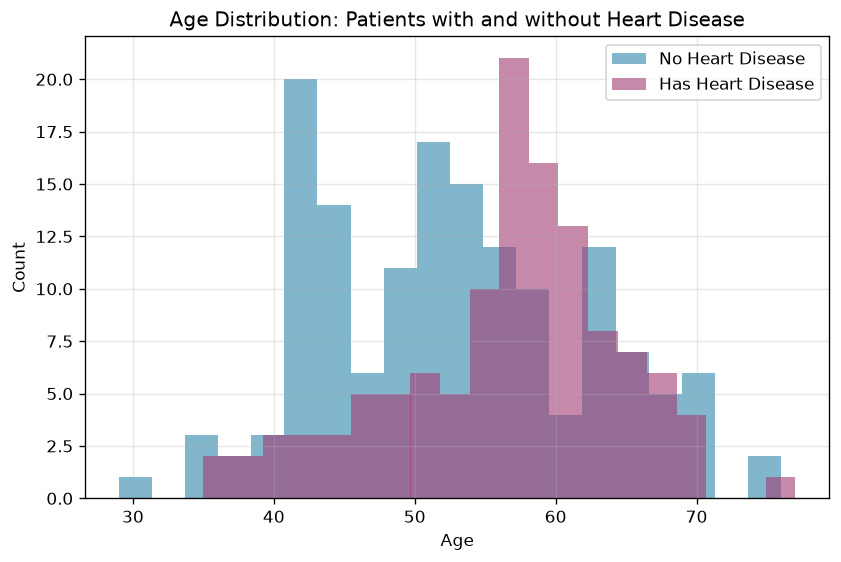

In [9]:
df_heart = pd.read_csv("heart.csv")

print("===== Heart Disease Dataset Preview =====")
print(df_heart.head())
print("\n===== Heart Disease Dataset Info =====")
print(df_heart.info())

df_heart["Heart_Disease_Binary"] = df_heart["Heart Disease"].map({"Presence":1, "Absence":0})

heart_positive = df_heart[df_heart["Heart_Disease_Binary"] == 1]
heart_negative = df_heart[df_heart["Heart_Disease_Binary"] == 0]

plt.figure(figsize=(8, 5))
plt.hist(heart_negative["Age"], bins=20, alpha=0.6, label="No Heart Disease", color="#2E86AB")
plt.hist(heart_positive["Age"], bins=20, alpha=0.6, label="Has Heart Disease", color="#A23B72")
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution: Patients with and without Heart Disease")
plt.legend()
plt.grid(alpha=0.3)
plt.show()